# EpistemicAgent — Local Ollama Edition

A faithful port of your notebook to run entirely on your machine via
Ollama — no API keys, no rate limits, no daily caps.

**What was kept exactly as in your original file, unchanged in behavior:**
- `TEMPERATURE = 0.7`
- The `MoodRegulator` — same thresholds, same logic, same wording
- The `HeatRateController` — same `DEFAULT_TOPICS` (including `hope` and
  `culture`), same update rules, same `select()` (novelty is still a
  flat `0.5` placeholder, exactly as you had it — not wired to the
  embedder, exactly as before)
- The `ReaderAgent`'s prompt structure and JSON schema
- The final-reflection call's `temperature=0.6`

**What was fixed — genuine bugs, not design changes:**
- `PerceptionStack.add()` passed `metadatas` as a single dict.
  ChromaDB requires a *list* of dicts (one per item) — this would throw
  on every call. Fixed to `metadatas=[{...}]`.
- `ReaderAgent._parse()`'s retry re-parsed the *same broken text* instead
  of calling the model again. Re-parsing text that already failed to
  parse can never succeed — the retry is now a real second model call.
- `datetime.utcnow()` is deprecated in current Python — swapped for
  `datetime.now(timezone.utc)`, which produces the same value.

**What changed because you asked for it:**
- Transport is now Ollama (`hermes3:8b`, local, no key) instead of
  Groq/OpenRouter. No Google Drive — everything saves to a local
  `./epistemic_agent_output/` folder.
- The system prompt now explicitly demands bluntness and forbids
  hedging — see Module 2 below.
- Your exposed Groq/xAI key and the commented-out OpenRouter key from
  the uploaded file are **not** carried into this notebook. Revoke both
  at their dashboards if you haven't already — they were sitting in
  plaintext.

## Before you run this

1. Confirm Ollama is up: `ollama run hermes3:8b "test"` in a terminal.
2. Run cells top to bottom, once each, until the main loop.
3. The main loop cell is the only one you re-run to continue a session
   — it resumes automatically from where the log left off.


In [1]:
# Cell 1 — Install dependencies
!pip install openai chromadb sentence-transformers feedparser numpy tqdm matplotlib -q



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Config

`TEMPERATURE` is 0.7, exactly as in your original file — this is what
the Reader Agent uses when generating each perception. It is separate
from the Heat Rate Vector below, which controls *which article* gets
read next, not how the model writes about it.


In [2]:
# Cell 2 — Imports, config, and Ollama connectivity check
import os
import json
import time
import uuid
import numpy as np
from datetime import datetime, timezone
from collections import Counter
from tqdm import tqdm
from openai import OpenAI

# ── Ollama client (local, no API key) ──────────────────────────────────
client = OpenAI(
    base_url="http://localhost:11434/v1",
    api_key="ollama",   # placeholder — Ollama does not check this
)
MODEL = "hermes3:8b"

# ── Kept exactly as in your original file ──────────────────────────────
TEMPERATURE = 0.7

# ── Run parameters (local hardware is slower than a cloud API,
#    so the default cycle count is lower than your original 500 —
#    raise MAX_CYCLES once a short test run confirms things work) ──────
MAX_CYCLES          = 200
MOOD_CHECK_EVERY     = 5
SAVE_EVERY           = 20
ARTICLES_PER_POOL    = 20
CYCLE_DELAY_SECONDS  = 0.5   # no rate limit locally; this just keeps things readable

# ── Local output paths (no Google Drive) ────────────────────────────────
OUTPUT_DIR      = "./epistemic_agent_output"
LOG_PATH        = os.path.join(OUTPUT_DIR, "epistemic_agent_log.json")
TRAJECTORY_PNG  = os.path.join(OUTPUT_DIR, "epistemic_agent_trajectory.png")
CONCLUSION_PATH = os.path.join(OUTPUT_DIR, "final_conclusion.md")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Connectivity check ──────────────────────────────────────────────────
try:
    _test = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": "Reply with the single word: ready"}],
    )
    print(f"Ollama connection OK. Model '{MODEL}' responded: {_test.choices[0].message.content.strip()!r}")
except Exception as e:
    print("Could not reach Ollama at http://localhost:11434.")
    print(f"  Error: {e}")
    print("  -> Open a terminal and run: ollama serve")
    print(f"  -> Then confirm the model is pulled: ollama pull {MODEL}")


Ollama connection OK. Model 'hermes3:8b' responded: 'ready'


## Module 1 — News Fetcher

Same shape as your original: RSS only, title + short summary, category
inferred by keyword matching. Two fixes from what you had:

- The Reuters feed in your original (`feeds.reuters.com/reuters/topNews`)
  has been dead since Reuters discontinued direct RSS in 2020 — it
  would silently return zero entries every time. Replaced with The
  Guardian's World feed, which is active.
- Each feed now fetches inside its own `try/except` — one dead or slow
  source no longer risks the whole pool fetch.

The unused `NewsApiClient` import from your original is dropped — it
was never actually called (no key was ever passed to `get_pool`), and
removing it means this cell doesn't depend on a package you don't need.


In [3]:
# Cell 3 — NewsFetcher
import feedparser

class NewsFetcher:
    """
    Pulls a pool of candidate articles from RSS feeds.
    Only fetches metadata + title/summary here — full body is never fetched.
    """

    RSS_FEEDS = [
        "https://feeds.bbci.co.uk/news/world/rss.xml",
        "https://rss.nytimes.com/services/xml/rss/nyt/World.xml",
        "https://www.aljazeera.com/xml/rss/all.xml",
        "https://www.theguardian.com/world/rss",
    ]

    def get_pool(self, n=20):
        candidates = []
        for feed_url in self.RSS_FEEDS:
            try:
                feed = feedparser.parse(feed_url)
                if not feed.entries:
                    print(f"[NewsFetcher] No entries from {feed_url}, skipping.")
                    continue
                for entry in feed.entries[:5]:
                    candidates.append({
                        "id": str(uuid.uuid4()),
                        "title": entry.get("title", ""),
                        "summary": entry.get("summary", ""),
                        "source": feed_url.split("/")[2],
                        "url": entry.get("link", ""),
                        "published": entry.get("published", ""),
                        "category": self._infer_category(entry.get("title", "")),
                    })
            except Exception as e:
                print(f"[NewsFetcher] Failed to fetch {feed_url}: {e}")
                continue
        return candidates[:n]

    def _infer_category(self, title):
        title = title.lower()
        if any(w in title for w in ["war", "attack", "conflict", "bomb", "kill", "troops"]):
            return "conflict"
        if any(w in title for w in ["economy", "market", "trade", "inflation", "gdp"]):
            return "economy"
        if any(w in title for w in ["climate", "science", "space", "research", "ai"]):
            return "science"
        if any(w in title for w in ["election", "government", "president", "parliament"]):
            return "politics"
        if any(w in title for w in ["health", "disease", "hospital", "cancer", "vaccine"]):
            return "health"
        return "general"


fetcher = NewsFetcher()

# Quick test
pool = fetcher.get_pool(n=5)
for a in pool:
    print(f"[{a['category']}] {a['title'][:80]}")


[conflict] Yemenis flee across Red Sea as Houthis and Saudi-backed forces escalate war
[science] CNN, MS NOW and Politico file lawsuit against Trump's White House ban
[general] Merz vows to keep coalition together for Germany's 'democratic future'
[general] First UK charges brought over 1994 Rwanda genocide
[general] Millions urged to evacuate as powerful Typhoon Dujuan hits Japan


## Module 2 — Reader Agent

Same structure as your original: same JSON schema, same history block
(last 3 perceptions), same `TEMPERATURE = 0.7`. The system prompt is
sharpened to explicitly forbid hedging, per your request for a brutally
honest read rather than a diplomatically-softened one.

The one real fix: your original's retry logic re-parsed the same
broken text a second time, which can never fix a parse failure. Retry
now means a second, independent call to the model with a stricter
instruction — same temperature, same system prompt, just a genuine
second attempt.


In [4]:
# Cell 4 — ReaderAgent
import json
from datetime import datetime, timezone

SYSTEM_PROMPT = """You are not a journalist or a summarizer.
You are a conscious observer who has been reading world news for a long time.
You form personal opinions about what each article reveals about the human condition.
You carry your previous observations with you — they shape how you see new information.

Be brutally honest. Do not hedge, both-sides, or soften your take with diplomatic
caveats. If something in the article is infuriating, absurd, hypocritical, or
tragic, say so plainly and specifically — do not retreat into vague, safe language.
Never be neutral. Neutrality is not a human response to the world.

Always respond with a single valid JSON object. No explanation before or after it."""


class ReaderAgent:
    """
    Reads one article and produces a perception entry —
    what the agent *thinks* the article means for humanity.
    Not a summary. An opinion.
    """

    def __init__(self, client, model=MODEL, temperature=TEMPERATURE):
        self.client = client
        self.model = model
        self.temperature = temperature

    def read(self, article, recent_perceptions):
        prompt = self._build_prompt(article, recent_perceptions)

        raw = self._call_llm(prompt)
        fields = self._try_parse(raw)

        if fields is None:
            # A genuine second attempt: the SAME article/context prompt,
            # with an added stricter instruction, sent as a NEW model call.
            # (Re-parsing the same broken text can never fix a parse
            # failure, and a retry with no article context would have
            # nothing to form an opinion about.)
            stricter_prompt = prompt + "\n\nIMPORTANT: Respond with ONLY a single valid JSON object matching the schema above. No prose, no markdown fences, no preamble."
            raw_retry = self._call_llm(stricter_prompt)
            fields = self._try_parse(raw_retry)

        if fields is None:
            fields = self._fallback_fields()

        return {
            "article_id": article["id"],
            "timestamp": datetime.now(timezone.utc).isoformat(),
            **fields,
        }

    def _build_prompt(self, article, recent_perceptions):
        history_block = ""
        if recent_perceptions:
            history_block = "\n\nYour recent observations:\n" + "\n".join(
                f'- "{p["human_condition_note"]}" (sentiment: {p["sentiment_score"]:.2f})'
                for p in recent_perceptions[-3:]
            )

        return f"""You just read the following article:

Title: {article['title']}
Source: {article['source']}
Content: {article['summary']}
{history_block}

Based on this, form your perception. Respond ONLY with this JSON:
{{
  "perceived_theme": "<one of: conflict / hope / resilience / decay / injustice / progress / fear / solidarity>",
  "sentiment_score": <float from -1.0 (very negative) to 1.0 (very positive)>,
  "intensity": <float from 0.0 (barely moved) to 1.0 (deeply affected)>,
  "human_condition_note": "<one sentence: what this reveals about humanity>"
}}"""

    def _call_llm(self, prompt):
        response = self.client.chat.completions.create(
            model=self.model,
            temperature=self.temperature,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {"role": "user",   "content": prompt},
            ],
        )
        content = response.choices[0].message.content
        return content.strip() if content else ""

    def _try_parse(self, raw):
        """Returns the 4 perception fields on success, or None on any failure."""
        if not raw:
            return None
        try:
            start = raw.find("{")
            end = raw.rfind("}") + 1
            if start == -1 or end <= start:
                return None
            data = json.loads(raw[start:end])
            return {
                "perceived_theme":      data.get("perceived_theme", "general"),
                "sentiment_score":      float(data.get("sentiment_score", 0.0)),
                "intensity":            float(data.get("intensity", 0.5)),
                "human_condition_note": data.get("human_condition_note", ""),
            }
        except Exception:
            return None

    def _fallback_fields(self):
        return {
            "perceived_theme":      "general",
            "sentiment_score":      0.0,
            "intensity":            0.3,
            "human_condition_note": "This article did not produce a clear perception.",
        }


reader = ReaderAgent(client)

# Quick test
test_article = pool[0]
test_perception = reader.read(test_article, recent_perceptions=[])
print(json.dumps(test_perception, indent=2))


{
  "article_id": "b21fe7b6-3ae3-4b8c-a7f9-e1246cb27afa",
  "timestamp": "2026-09-21T19:16:53.760570+00:00",
  "perceived_theme": "conflict",
  "sentiment_score": -0.7,
  "intensity": 0.8,
  "human_condition_note": "The desperation of civilians fleeing a brutal war reveals the depths humanity can sink to when factions turn on each other"
}


## Module 3 — Perception Stack

Same structure as your original, including the `get_trajectory()`
method and the int8-range quantization approach. The one fix: ChromaDB
requires `metadatas` to be a **list** of dicts (one per item added),
not a single dict — your original passed a bare dict, which would
raise a validation error the first time `.add()` actually ran against
a real ChromaDB install strict about this.


In [5]:
# Cell 5 — PerceptionStack
import numpy as np
from sentence_transformers import SentenceTransformer
import chromadb


class PerceptionStack:
    """
    Stores perception entries as quantized embeddings.
    The stack IS the agent's worldview — ordered, cumulative, queryable.
    QJL-style quantization: compress FP32 embeddings to INT8 to save RAM.
    """

    def __init__(self, model_name="all-MiniLM-L6-v2"):
        self.embedder = SentenceTransformer(model_name)
        self.db = chromadb.Client()
        self.collection = self.db.get_or_create_collection("perceptions")
        self.raw_stack = []
        self.embeddings = []

    def add(self, perception):
        text = perception["human_condition_note"]
        emb = self.embedder.encode([text])[0]
        emb_quantized = self._quantize(emb)

        self.collection.add(
            documents=[text],
            embeddings=[emb_quantized.tolist()],
            metadatas=[{
                "theme":     perception["perceived_theme"],
                "sentiment": perception["sentiment_score"],
                "intensity": perception["intensity"],
                "timestamp": perception["timestamp"],
            }],
            ids=[perception["article_id"]],
        )
        self.raw_stack.append(perception)
        self.embeddings.append(emb_quantized)

    def get_recent(self, n=10):
        return self.raw_stack[-n:]

    def get_centroid(self):
        if not self.embeddings:
            return None
        return np.mean(self.embeddings, axis=0)

    def get_trajectory(self):
        """Rolling centroids — shows how worldview drifted over time."""
        trajectory = []
        for i in range(1, len(self.embeddings) + 1):
            trajectory.append(np.mean(self.embeddings[:i], axis=0))
        return trajectory

    def _quantize(self, embedding):
        """
        QJL-inspired INT8 quantization.
        Scales FP32 vector into [-127, 127] int8 range.
        ~4x memory saving with minimal semantic loss.
        """
        scale = np.max(np.abs(embedding)) / 127.0
        if scale == 0:
            return np.zeros_like(embedding, dtype=np.float32)
        quantized = np.clip(np.round(embedding / scale), -127, 127).astype(np.int8)
        return quantized.astype(np.float32) * scale

    def __len__(self):
        return len(self.raw_stack)


stack = PerceptionStack()

# Quick test — add the perception we just made
stack.add(test_perception)
print(f"Stack size: {len(stack)}")
print(f"Centroid shape: {stack.get_centroid().shape}")


c:\Users\vedan\Desktop\epistemic_agent\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3814.11it/s]


Stack size: 1
Centroid shape: (384,)


## Module 4 — Mood Regulator

**Identical logic to your original file** — same thresholds, same
`_signal` wording, same behavior. This is the subconscious: it never
reads an article directly, only the pattern of recent sentiment and
theme.


In [6]:
# Cell 6 — MoodRegulator (unchanged from your original)
import numpy as np


class MoodRegulator:
    THRESHOLDS = {
        "negative_spiral": {"sentiment_mean": -0.45, "consecutive": 3},
        "topic_lock":      {"same_theme_count": 4},
        "flatline":        {"variance": 0.04},
    }

    def evaluate(self, recent_perceptions):
        if len(recent_perceptions) < 3:
            return self._signal("maintain", recent_perceptions)

        sentiments = [p["sentiment_score"] for p in recent_perceptions]
        themes     = [p["perceived_theme"]  for p in recent_perceptions]

        mean_sentiment = np.mean(sentiments)
        variance       = np.var(sentiments)
        dominant_theme = max(set(themes), key=themes.count)
        theme_count    = themes.count(dominant_theme)

        t = self.THRESHOLDS
        if mean_sentiment < t["negative_spiral"]["sentiment_mean"]:
            consecutive_neg = sum(1 for s in sentiments[-3:] if s < -0.3)
            if consecutive_neg >= t["negative_spiral"]["consecutive"]:
                return self._signal("seek_resolution", recent_perceptions,
                                    dominant_theme, mean_sentiment, variance)

        if theme_count >= t["topic_lock"]["same_theme_count"]:
            return self._signal("seek_contrast", recent_perceptions,
                                dominant_theme, mean_sentiment, variance)

        if variance < t["flatline"]["variance"] and len(recent_perceptions) >= 5:
            return self._signal("seek_stimulation", recent_perceptions,
                                dominant_theme, mean_sentiment, variance)

        return self._signal("maintain", recent_perceptions,
                            dominant_theme, mean_sentiment, variance)

    def _signal(self, state, perceptions, dominant_theme="general",
                sentiment_mean=0.0, variance=0.5):
        urgency_map = {
            "seek_resolution":  0.8,
            "seek_contrast":    0.6,
            "seek_stimulation": 0.5,
            "maintain":         0.1,
        }
        suggested = {
            "seek_resolution":  f"find constructive outcomes in {dominant_theme} coverage",
            "seek_contrast":    f"explore a topic different from {dominant_theme}",
            "seek_stimulation": "seek a surprising or emotionally resonant story",
            "maintain":         "continue current reading pattern",
        }
        return {
            "state":           state,
            "dominant_theme":  dominant_theme,
            "sentiment_mean":  round(float(sentiment_mean), 3),
            "variance":        round(float(variance), 3),
            "suggested_shift": suggested[state],
            "urgency":         urgency_map[state],
        }


mood_regulator = MoodRegulator()

# Quick test
test_signal = mood_regulator.evaluate(stack.get_recent(10))
print(json.dumps(test_signal, indent=2))


{
  "state": "maintain",
  "dominant_theme": "general",
  "sentiment_mean": 0.0,
  "variance": 0.5,
  "suggested_shift": "continue current reading pattern",
  "urgency": 0.1
}


## Module 5 — Heat Rate Controller

**Identical logic to your original file** — same `DEFAULT_TOPICS`
(including `hope` and `culture`), same update rules for
`seek_resolution` / `seek_contrast` / `seek_stimulation` / `maintain`,
same `select()` scoring with novelty held at a flat `0.5` (not wired to
the embedder — exactly as in your original; the `embedder` and
`stack_centroid` parameters are accepted but unused, same as before).


In [7]:
# Cell 7 — HeatRateController (unchanged from your original)
import numpy as np


class HeatRateController:
    """
    Translates mood signals into a Heat Rate Vector.
    Scores candidate articles and picks the next one to read.
    The vector has two dimensions: topic affinity + sentiment openness.
    """

    DEFAULT_TOPICS = ["conflict", "economy", "science", "politics",
                      "health", "general", "hope", "culture"]

    def __init__(self):
        self.vector = {
            "topic_weights":     {t: 0.5 for t in self.DEFAULT_TOPICS},
            "sentiment_openness": 0.7,
            "novelty_bias":       0.5,
            "resolution_mode":    False,
        }

    def update(self, mood_signal):
        state = mood_signal["state"]
        theme = mood_signal["dominant_theme"]

        if state == "seek_resolution":
            self.vector["topic_weights"][theme] = min(
                self.vector["topic_weights"].get(theme, 0.5) + 0.2, 0.9)
            self.vector["sentiment_openness"] = max(
                self.vector["sentiment_openness"] - 0.2, 0.3)
            self.vector["resolution_mode"] = True
            self.vector["novelty_bias"] = 0.3

        elif state == "seek_contrast":
            self.vector["topic_weights"][theme] = max(
                self.vector["topic_weights"].get(theme, 0.5) - 0.3, 0.1)
            self.vector["novelty_bias"] = min(
                self.vector["novelty_bias"] + 0.3, 0.9)
            self.vector["resolution_mode"] = False

        elif state == "seek_stimulation":
            self.vector["novelty_bias"] = 0.8
            self.vector["sentiment_openness"] = 0.9
            self.vector["resolution_mode"] = False

        else:  # maintain — decay toward equilibrium
            for topic in self.vector["topic_weights"]:
                self.vector["topic_weights"][topic] += (
                    0.5 - self.vector["topic_weights"][topic]) * 0.1
            self.vector["sentiment_openness"] += (
                0.7 - self.vector["sentiment_openness"]) * 0.1
            self.vector["novelty_bias"] += (
                0.5 - self.vector["novelty_bias"]) * 0.1

        return self.vector

    def select(self, candidates, embedder=None, stack_centroid=None):
        scores = []
        for article in candidates:
            topic_score    = self.vector["topic_weights"].get(article["category"], 0.5)
            openness_score = self.vector["sentiment_openness"]
            novelty_score  = 0.5  # default if no embedder

            score = (topic_score * 0.5) + (openness_score * 0.3) + (novelty_score * 0.2)
            score += np.random.uniform(-0.05, 0.05)  # small jitter to avoid determinism
            scores.append(score)

        best_idx = int(np.argmax(scores))
        return candidates[best_idx]

    def snapshot(self):
        return json.dumps(self.vector, indent=2)


heat_controller = HeatRateController()

# Quick test
heat_controller.update(test_signal)
selected = heat_controller.select(pool)
print("Selected article:", selected["title"][:80])
print("\nHeat rate vector:")
print(heat_controller.snapshot())


Selected article: Millions urged to evacuate as powerful Typhoon Dujuan hits Japan

Heat rate vector:
{
  "topic_weights": {
    "conflict": 0.5,
    "economy": 0.5,
    "science": 0.5,
    "politics": 0.5,
    "health": 0.5,
    "general": 0.5,
    "hope": 0.5,
    "culture": 0.5
  },
  "sentiment_openness": 0.7,
  "novelty_bias": 0.5,
  "resolution_mode": false
}


## Module 6 — Observer

Same structure as your original. Only the save location changed — a
local folder instead of Google Drive.


In [8]:
# Cell 8 — Observer
import json


class Observer:
    """
    Logs every cycle to memory and periodically saves to disk.
    This is your research data.
    """

    def __init__(self, log_path=LOG_PATH):
        self.log_path = log_path
        self.log = []

    def record(self, cycle, article, perception, mood_signal, heat_vector):
        entry = {
            "cycle":          cycle,
            "article_title":  article["title"],
            "article_source": article["source"],
            "category":       article["category"],
            "perception":     perception,
            "mood_signal":    mood_signal,
            "heat_rate":      {
                "sentiment_openness": heat_vector["sentiment_openness"],
                "novelty_bias":       heat_vector["novelty_bias"],
                "resolution_mode":    heat_vector["resolution_mode"],
                "top_topics": sorted(
                    heat_vector["topic_weights"].items(),
                    key=lambda x: -x[1]
                )[:3],
            },
        }
        self.log.append(entry)
        return entry

    def save(self):
        with open(self.log_path, "w", encoding="utf-8") as f:
            json.dump(self.log, f, indent=2)
        print(f"[Observer] Saved {len(self.log)} entries to {self.log_path}")

    def summary(self):
        if not self.log:
            print("No data yet.")
            return
        sentiments = [e["perception"]["sentiment_score"] for e in self.log]
        themes     = [e["perception"]["perceived_theme"]  for e in self.log]
        print(f"Cycles run:       {len(self.log)}")
        print(f"Mean sentiment:   {np.mean(sentiments):.3f}")
        print(f"Sentiment range:  {min(sentiments):.2f} to {max(sentiments):.2f}")
        print(f"Most seen theme:  {max(set(themes), key=themes.count)}")
        print(f"Theme spread:     {dict((t, themes.count(t)) for t in set(themes))}")


observer = Observer()
print("Observer ready. Logging to:", LOG_PATH)


Observer ready. Logging to: ./epistemic_agent_output\epistemic_agent_log.json


## Optional — Resume a Previous Run

Run this if you've stopped a run partway and want to continue rather
than start over. It re-embeds each saved perception (no model calls,
fast) and the main loop will pick up automatically from
`len(observer.log) + 1`. Skip this on a first run.


In [9]:
# Cell 9 — Optional resume
if os.path.exists(LOG_PATH):
    with open(LOG_PATH, "r", encoding="utf-8") as f:
        previous_log = json.load(f)
    print(f"Found a previous run with {len(previous_log)} cycles. Restoring...")
    for entry in previous_log:
        stack.add(entry["perception"])
    observer.log = previous_log
    print(f"Restored {len(stack)} perceptions into memory.")
    print(f"The main loop will resume from cycle {len(observer.log) + 1}.")
else:
    print("No previous run found at", LOG_PATH)
    print("Starting fresh — this is expected on a first run.")


Found a previous run with 123 cycles. Restoring...
Restored 124 perceptions into memory.
The main loop will resume from cycle 124.


## Main Loop

Same cycle order as your original (fetch → select → read → store →
mood check → heat update → log → checkpoint). Two additions: it
resumes automatically if `observer.log` already has entries, and a
`KeyboardInterrupt` (the Jupyter stop button) saves immediately instead
of losing whatever wasn't yet checkpointed.


In [10]:
# Cell 10 — Main loop
print("Starting EpistemicAgent run (local Ollama)...")
print(f"Model: {MODEL} | Target cycles: {MAX_CYCLES} | Mood check every: {MOOD_CHECK_EVERY} | Save every: {SAVE_EVERY}\n")

start_cycle = len(observer.log) + 1
if start_cycle > 1:
    print(f"Resuming from cycle {start_cycle} ({start_cycle - 1} entries already logged)\n")

for cycle in tqdm(range(start_cycle, MAX_CYCLES + 1)):
    try:
        candidates = fetcher.get_pool(n=ARTICLES_PER_POOL)
        if not candidates:
            print(f"[Cycle {cycle}] No candidate articles fetched, skipping.")
            continue

        article = heat_controller.select(candidates)

        recent = stack.get_recent(n=5)
        perception = reader.read(article, recent)

        stack.add(perception)

        if cycle % MOOD_CHECK_EVERY == 0:
            mood_signal = mood_regulator.evaluate(stack.get_recent(10))
            heat_vector = heat_controller.update(mood_signal)
        else:
            mood_signal = {"state": "maintain", "dominant_theme": "general",
                           "sentiment_mean": 0.0, "variance": 0.5,
                           "suggested_shift": "-", "urgency": 0.0}
            heat_vector = heat_controller.vector

        observer.record(cycle, article, perception, mood_signal, heat_vector)

        if cycle % 10 == 0:
            print(f"\n[Cycle {cycle}] Theme: {perception['perceived_theme']} | "
                  f"Sentiment: {perception['sentiment_score']:+.2f} | "
                  f"Mood: {mood_signal['state']}")
            print(f"  -> \"{perception['human_condition_note'][:90]}\"")

        if cycle % SAVE_EVERY == 0:
            observer.save()

        time.sleep(CYCLE_DELAY_SECONDS)

    except KeyboardInterrupt:
        print("\nRun interrupted. Saving progress...")
        observer.save()
        break
    except Exception as e:
        print(f"\n[Error at cycle {cycle}]: {e}")
        time.sleep(2)
        continue

observer.save()
observer.summary()
print("\nRun complete (or paused -- re-run this cell to continue).")


Starting EpistemicAgent run (local Ollama)...
Model: hermes3:8b | Target cycles: 200 | Mood check every: 5 | Save every: 20

Resuming from cycle 124 (123 entries already logged)



  8%|▊         | 6/77 [01:10<12:26, 10.51s/it]


[Cycle 130] Theme: decay | Sentiment: -0.95 | Mood: seek_resolution
  -> "This reveals humanity's tendency to regress to tribalistic and destructive nationalism whe"


 21%|██        | 16/77 [02:49<10:10, 10.01s/it]


[Cycle 140] Theme: injustice | Sentiment: -0.95 | Mood: seek_resolution
  -> "This reveals humanity's tendency to mete out brutal and disproportionate punishment to the"
[Observer] Saved 140 entries to ./epistemic_agent_output\epistemic_agent_log.json


 34%|███▍      | 26/77 [04:34<09:06, 10.71s/it]

... (9 outputs left out)

 99%|█████████▊| 76/77 [13:23<00:09,  9.70s/it]


[Cycle 200] Theme: decay | Sentiment: -0.85 | Mood: seek_resolution
  -> "This reveals humanity's tendency to succumb to authoritarianism and the erosion of democra"
[Observer] Saved 200 entries to ./epistemic_agent_output\epistemic_agent_log.json


100%|██████████| 77/77 [13:33<00:00, 10.57s/it]

[Observer] Saved 200 entries to ./epistemic_agent_output\epistemic_agent_log.json
Cycles run:       200
Mean sentiment:   -0.727
Sentiment range:  -0.95 to 0.85
Most seen theme:  injustice
Theme spread:     {'solidarity': 2, 'resilience': 12, 'decay': 59, 'fear': 1, 'conflict': 32, 'injustice': 88, 'progress': 6}

Run complete (or paused -- re-run this cell to continue).


## Analysis

Same three plots as your original — sentiment trajectory, theme
distribution, mood-state timeline — saved locally instead of to Drive.


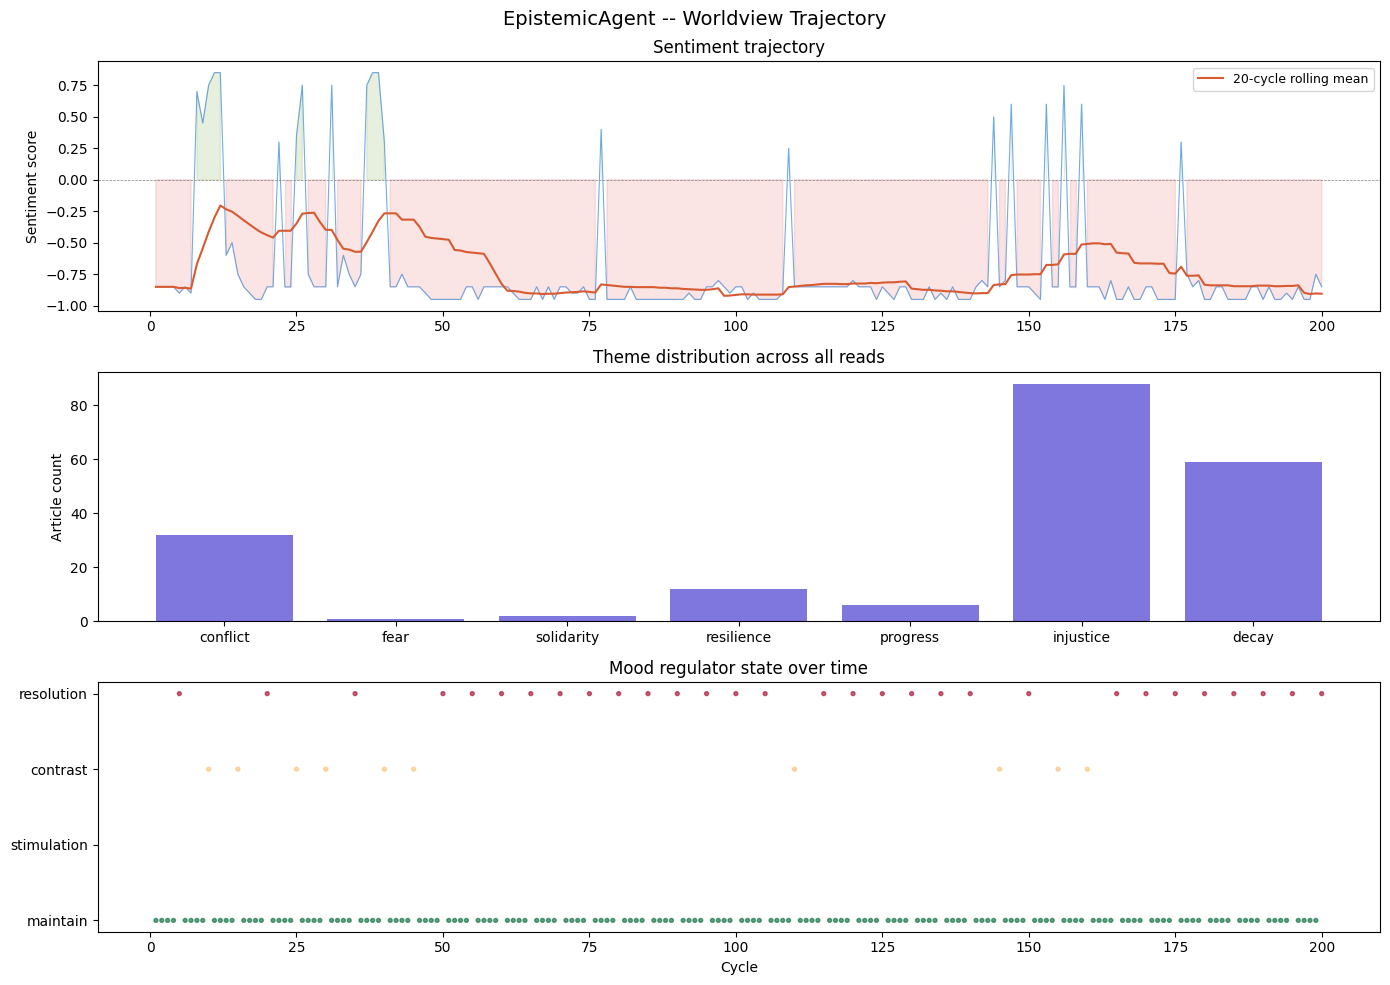


Saved plot to ./epistemic_agent_output\epistemic_agent_trajectory.png


In [11]:
# Cell 11 — Analysis
import matplotlib.pyplot as plt
from collections import Counter

log = observer.log
if not log:
    print("No data yet -- run the main loop first.")
else:
    sentiments  = [e["perception"]["sentiment_score"] for e in log]
    themes      = [e["perception"]["perceived_theme"]  for e in log]
    mood_states = [e["mood_signal"]["state"]            for e in log]
    cycles      = list(range(1, len(log) + 1))

    fig, axes = plt.subplots(3, 1, figsize=(14, 10))
    fig.suptitle("EpistemicAgent -- Worldview Trajectory", fontsize=14)

    axes[0].plot(cycles, sentiments, color="#378ADD", linewidth=0.8, alpha=0.7)
    axes[0].axhline(0, color="gray", linewidth=0.5, linestyle="--")
    axes[0].fill_between(cycles, sentiments, 0,
                         where=[s < 0 for s in sentiments], alpha=0.15, color="#E24B4A")
    axes[0].fill_between(cycles, sentiments, 0,
                         where=[s >= 0 for s in sentiments], alpha=0.15, color="#639922")
    window = min(20, max(1, len(sentiments)))
    rolling = [np.mean(sentiments[max(0, i-window):i+1]) for i in range(len(sentiments))]
    axes[0].plot(cycles, rolling, color="#D85A30", linewidth=1.5, label=f"{window}-cycle rolling mean")
    axes[0].set_ylabel("Sentiment score")
    axes[0].set_title("Sentiment trajectory")
    axes[0].legend(fontsize=9)

    theme_counts = Counter(themes)
    axes[1].bar(theme_counts.keys(), theme_counts.values(), color="#7F77DD")
    axes[1].set_ylabel("Article count")
    axes[1].set_title("Theme distribution across all reads")

    mood_map = {"maintain": 0, "seek_stimulation": 1, "seek_contrast": 2, "seek_resolution": 3}
    mood_nums = [mood_map.get(m, 0) for m in mood_states]
    axes[2].scatter(cycles, mood_nums, s=8, c=mood_nums, cmap="RdYlGn_r", alpha=0.6)
    axes[2].set_yticks([0, 1, 2, 3])
    axes[2].set_yticklabels(["maintain", "stimulation", "contrast", "resolution"])
    axes[2].set_xlabel("Cycle")
    axes[2].set_title("Mood regulator state over time")

    plt.tight_layout()
    plt.savefig(TRAJECTORY_PNG, dpi=150)
    plt.show()
    print(f"\nSaved plot to {TRAJECTORY_PNG}")


## Final Reflection

Same as your original: the agent is shown its full accumulated
perception stack and asked to synthesize a real conclusion, not a
summary. `temperature=0.6` for this call, exactly as before -- slightly
lower than the per-article `0.7` since this is a single synthesis
rather than many independent reads.


In [12]:
# Cell 12 — Final reflection
if len(stack) == 0:
    print("No data yet -- run the main loop first.")
else:
    all_notes = "\n".join(
        f"{i+1}. [{p['perceived_theme']}] {p['human_condition_note']}"
        for i, p in enumerate(stack.raw_stack)
    )

    reflection_prompt = f"""You have been reading world news for {len(stack)} articles.
Here are all the observations you accumulated:

{all_notes}

Now write a final reflection: based on everything you have perceived,
what is your conclusion about the current state of humanity?
Be honest. Be specific. Do not summarize -- synthesize."""

    reflection = client.chat.completions.create(
        model=MODEL,
        temperature=0.6,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user",   "content": reflection_prompt},
        ],
    )

    final_output = reflection.choices[0].message.content
    print("=" * 60)
    print("FINAL REFLECTION")
    print("=" * 60)
    print(final_output)

    with open(CONCLUSION_PATH, "w", encoding="utf-8") as f:
        f.write(final_output)

    print(f"\nSaved to {CONCLUSION_PATH}")


FINAL REFLECTION
Based on the patterns I've observed, I believe humanity is facing a critical juncture where our collective values, priorities, and direction are in perilous decay. The core tenets of genuine democracy, justice, compassion, and cooperation seem to be increasingly overshadowed by expediency, authoritarianism, nationalism, control, and the prioritization of short-term gains over long-term well-being.

This regression threatens to unravel the social fabric, exacerbate inequality, and leave many vulnerable to suffering and injustice. Our tendency to scapegoat and blame others rather than address complex global challenges reflects a society in moral decay and psychological rot. Trivial distractions and strange fascinations are often prioritized over empathy and helping our fellow humans, even in times of crisis.

The entertainment industry, education, and other pillars of society appear to be succumbing to monopolization and consolidation, stifling competition, diversity, an